In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

housing = fetch_california_housing(as_frame=True)
X, y = housing.data, housing.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

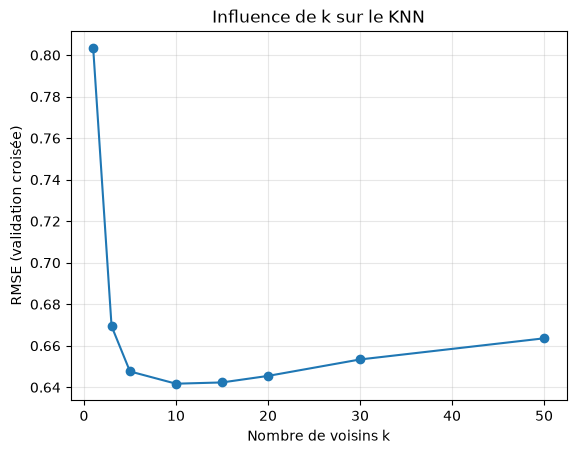

Meilleur k : 10


In [2]:
ks = [1, 3, 5, 10, 15, 20, 30, 50]
rmse_k = []
for k in ks:
    modele = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k))
    scores = cross_val_score(modele, X_train, y_train, cv=5,
                             scoring="neg_root_mean_squared_error", n_jobs=-1)
    rmse_k.append(-scores.mean())

plt.plot(ks, rmse_k, marker="o")
plt.xlabel("Nombre de voisins k"); plt.ylabel("RMSE (validation croisée)")
plt.title("Influence de k sur le KNN")
plt.grid(alpha=0.3)
plt.savefig("../figures/knn_k.png", dpi=150)
plt.show()
print("Meilleur k :", ks[int(np.argmin(rmse_k))])

In [3]:
grid_ridge = GridSearchCV(
    make_pipeline(StandardScaler(), Ridge()),
    {"ridge__alpha": [0.01, 0.1, 1, 10, 100, 1000]},
    cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1
)
grid_ridge.fit(X_train, y_train)
print("Meilleur α :", grid_ridge.best_params_, "– RMSE CV :", -grid_ridge.best_score_)

Meilleur α : {'ridge__alpha': 0.01} – RMSE CV : 0.7205271904045847


In [4]:
params = {
    "learning_rate": [0.03, 0.05, 0.1, 0.2],
    "max_iter": [200, 400, 800],
    "max_leaf_nodes": [15, 31, 63],
    "min_samples_leaf": [10, 20, 50],
    "l2_regularization": [0.0, 0.1, 1.0],
}
recherche = RandomizedSearchCV(
    HistGradientBoostingRegressor(random_state=42),
    params, n_iter=25, cv=3, scoring="neg_root_mean_squared_error",
    random_state=42, n_jobs=-1, verbose=1
)
recherche.fit(X_train, y_train)
print("Meilleurs paramètres :", recherche.best_params_)
print("RMSE CV :", -recherche.best_score_)

Fitting 3 folds for each of 25 candidates, totalling 75 fits
Meilleurs paramètres : {'min_samples_leaf': 20, 'max_leaf_nodes': 63, 'max_iter': 800, 'learning_rate': 0.03, 'l2_regularization': 0.0}
RMSE CV : 0.46572883104477775


In [5]:
final = recherche.best_estimator_
pred = final.predict(X_test)
print(f"MAE  : {mean_absolute_error(y_test, pred):.3f}")
print(f"RMSE : {root_mean_squared_error(y_test, pred):.3f}")
print(f"R²   : {r2_score(y_test, pred):.3f}")

MAE  : 0.293
RMSE : 0.448
R²   : 0.847
